In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from scipy import stats


pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

In [4]:
# import dataset
DATA_PATH = "D:\\SemesterI_2026-27\\Prob&stats\\Lab\\Day1_WK\\Data\\application_train.csv" 


In [5]:
SPLITS_DIR = "D:\\SemesterI_2026-27\\Prob&stats\\Lab\\Day1_WK\\Data\\splits"

In [6]:
# Load the dataset
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.info()

(307511, 122)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [7]:
df.head(10)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,...,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,...,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,...,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,...,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,...,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,1,0,0,Core staff,1.0,...,0.0,0.0,0.0,-1106.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
5,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,454500.0,"Spouse, partner",State servant,Secondary / secondary special,Married,House / apartment,0.035792,-16941,-1588,-4970.0,-477,NaN,1,1,1,1,1,0,Laborers,2.0,...,0.0,0.0,0.0,-2536.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0
6,100009,0,Cash loans,F,Y,Y,1,171000.0,1560726.0,41301.0,1395000.0,Unaccompanied,Commercial associate,Higher education,Married,House / apartment,0.035792,-13778,-3130,-1213.0,-619,17.0,1,1,0,1,1,0,Accountants,3.0,...,0.0,1.0,0.0,-1562.0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0.0,0.0,0.0,1.0,1.0,2.0
7,100010,0,Cash loans,M,Y,Y,0,360000.0,1530000.0,42075.0,1530000.0,Unaccompanied,State servant,Higher education,Married,House / apartment,0.003122,-18850,-449,-4597.0,-2379,8.0,1,1,1,1,0,0,Managers,2.0,...,0.0,2.0,0.0,-1070.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
8,100011,0,Cash loans,F,N,Y,0,112500.0,1019610.0,33826.5,913500.0,Children,Pensioner,Secondary / secondary special,Married,House / apartment,0.018634,-20099,365243,-7427.0,-3514,NaN,1,0,0,1,0,0,NaN,2.0,...,0.0,1.0,0.0,0.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
9,100012,0,Revolving loans,M,N,Y,0,135000.0,405000.0,20250.0,405000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.019689,-14469,-2019,-14437.0,-3992,NaN,1,1,0,1,0,0,Laborers,1.0,...,0.0,2.0,0.0,-1673.0,0,0,0,0,0,0

In [8]:
#data-type summary
dtype_summary = (
    df.dtypes
    .astype(str)
    .value_counts()
    .rename_axis("data_type")
    .reset_index(name="column_count")
)

dtype_summary

,data_type,column_count
0,float64,65
1,int64,41
2,object,16


In [9]:
# Validate required columns
ID_COLUMN = "SK_ID_CURR"
TARGET_COLUMN = "TARGET"
required_columns = {
    ID_COLUMN,
    TARGET_COLUMN,
}

missing_required_columns = required_columns - set(df.columns)

if missing_required_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_required_columns)}"
    )

print("Required columns are present.")

Required columns are present.


In [10]:
#Inspect the identifier
identifier_audit = {
    "row_count": len(df),
    "non_missing_ids": int(df[ID_COLUMN].notna().sum()),
    "missing_ids": int(df[ID_COLUMN].isna().sum()),
    "unique_ids": int(df[ID_COLUMN].nunique()),
    "duplicated_ids": int(df[ID_COLUMN].duplicated().sum()),
}

pd.Series(identifier_audit, name="value")

row_count          307511
non_missing_ids    307511
missing_ids             0
unique_ids         307511
duplicated_ids          0
Name: value, dtype: int64

In [11]:
# Check for exact duplicate rows
exact_duplicate_count = int(df.duplicated().sum())

print(f"Exact duplicate rows: {exact_duplicate_count:,}")

Exact duplicate rows: 0


In [12]:
# Check duplicates after excluding the identifier:
columns_without_id = [
    column
    for column in df.columns
    if column != ID_COLUMN
]

duplicate_without_id_count = int(
    df[columns_without_id].duplicated().sum()
)

print(
    "Rows duplicated after excluding the identifier: "
    f"{duplicate_without_id_count:,}"
)

Rows duplicated after excluding the identifier: 0


In [13]:
#Validate the target
target_missing_count = int(
    df[TARGET_COLUMN].isna().sum()
)

target_values = set(
    df[TARGET_COLUMN]
    .dropna()
    .unique()
)

print(f"Missing target values: {target_missing_count:,}")
print(f"Observed target values: {sorted(target_values)}")

Missing target values: 0
Observed target values: [np.int64(0), np.int64(1)]


Lets calculate Target Distribution

In [14]:
target_counts = (
    df[TARGET_COLUMN]
    .value_counts()
    .sort_index()
)

target_percentages = (df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

target_distribution = pd.DataFrame({
    "count": target_counts,
    "percentage": target_percentages,
})

target_distribution.index.name = "TARGET"
target_distribution

,count,percentage
TARGET,,
0,282686,91.927118
1,24825,8.072882


In [15]:
RANDOM_STATE = 42
TRAIN_SIZE = 0.70
VALIDATION_SIZE = 0.15
TEST_SIZE = 0.15
train_df, holdout_df = train_test_split(
    df,
    test_size=VALIDATION_SIZE + TEST_SIZE,
    stratify=df[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

In [16]:
relative_test_size = TEST_SIZE / (
    VALIDATION_SIZE + TEST_SIZE
)

print(f"Relative test size within holdout: {relative_test_size:.2f}")

Relative test size within holdout: 0.50


In [17]:
# split the holdout set into validation and test sets
validation_df, test_df = train_test_split(
    holdout_df,
    test_size=relative_test_size,
    stratify=holdout_df[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

Inspect partition dimensions

In [18]:
split_sizes = pd.DataFrame({
    "partition": ["training", "validation", "test"],
    "rows": [
        len(train_df),
        len(validation_df),
        len(test_df),
    ],
})

split_sizes["percentage"] = (
    split_sizes["rows"] / len(df) * 100
)

split_sizes

,partition,rows,percentage
0,training,215257,69.999772
1,validation,46127,15.000114
2,test,46127,15.000114


In [19]:
def summarize_target(dataframe, partition_name):
    counts = dataframe[TARGET_COLUMN].value_counts().sort_index()
    percentages = (
        dataframe[TARGET_COLUMN]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
    )

    return {
        "partition": partition_name,
        "rows": len(dataframe),
        "target_0_count": int(counts.get(0, 0)),
        "target_1_count": int(counts.get(1, 0)),
        "target_1_percentage": float(percentages.get(1, 0)),
    }


split_target_summary = pd.DataFrame([
    summarize_target(train_df, "training"),
    summarize_target(validation_df, "validation"),
    summarize_target(test_df, "test"),
])

split_target_summary

,partition,rows,target_0_count,target_1_count,target_1_percentage
0,training,215257,197880,17377,8.072676
1,validation,46127,42403,3724,8.073363
2,test,46127,42403,3724,8.073363


EDA:Understand every feature independently, identify data-quality risks, and create a documented treatment decision for missing values, anomalies, constants, rare categories and invalid ranges.

EDA Questions:
1. What decision does this data ultimately feed into, and what are the two ways that decision can go wrong?
2. What fraction of applicants does the client currently expect to default? Is this dataset likely to reflect that real-world rate, or could it be biased
3. Which fields would you personally trust least, just from their names, before looking at a single value?


In [20]:
# configure display options for better visualization
pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 150)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

sns.set_theme(
    style="whitegrid",
    context="notebook",
)

RANDOM_STATE = 42
ID_COLUMN = "SK_ID_CURR"
TARGET_COLUMN = "TARGET"

In [21]:
# only use train part for EDA and feature engineering, keep validation and test sets untouched
eda_df = train_df.copy()

print(f"EDA rows: {len(eda_df):,}")
print(f"EDA columns: {eda_df.shape[1]:,}")

EDA rows: 215,257
EDA columns: 122


In [22]:
# Separate identifier, target and candidate features
excluded_columns = {
    ID_COLUMN,
    TARGET_COLUMN,
}

feature_columns = [
    column
    for column in eda_df.columns
    if column not in excluded_columns
]

numerical_columns = (
    eda_df[feature_columns]
    .select_dtypes(include="number")
    .columns
    .tolist()
)

categorical_columns = (
    eda_df[feature_columns]
    .select_dtypes(
        include=["object", "category", "string"]
    )
    .columns
    .tolist()
)

print(f"Candidate features: {len(feature_columns)}")
print(f"Numerical features: {len(numerical_columns)}")
print(f"Categorical features: {len(categorical_columns)}")

Candidate features: 120
Numerical features: 104
Categorical features: 16


1. Univariate EDA: Examine one feature at a time without comparing it with TARGET.

In [37]:
 # 1.1 Numerical features summary
eda_df.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"215,257.000","278,405.903","102,802.244","100,002.000","189,384.000","278,524.000","367,362.000","456,255.000"
TARGET,"215,257.000",0.081,0.272,0.000,0.000,0.000,0.000,1.000
CNT_CHILDREN,"215,257.000",0.417,0.720,0.000,0.000,0.000,1.000,19.000
AMT_INCOME_TOTAL,"215,257.000","169,084.258","274,245.234","25,650.000","112,500.000","148,500.000","202,500.000","117,000,000.000"
AMT_CREDIT,"215,257.000","599,416.427","402,647.708","45,000.000","270,000.000","516,397.500","808,650.000","4,050,000.000"
AMT_ANNUITY,"215,249.000","27,116.966","14,549.965","1,615.500","16,524.000","24,903.000","34,587.000","258,025.500"
AMT_GOODS_PRICE,"215,070.000","538,818.967","369,641.133","40,500.000","238,500.000","450,000.000","679,500.000","4,050,000.000"
REGION_POPULATION_RELATIVE,"215,257.000",0.021,0.014,0.000,0.010,0.019,0.029,0.073
DAYS_BIRTH,"215,257.000","-16,034.389","4,361.550","-25,200.000","-19,683.000","-15,745.000","-12,409.000","-7,673.000"
DAYS_EMPLOYED,"215,257.000","63,803.531","141,268.681","-17,583.000","-2,761.000","-1,213.000",-289.000,"365,243.000"


Result Analysis: #1 Why is the mean of TARGET equal to 0.081? Approximately 8.1% of training applicants experienced repayment difficulty.This indicates a significant class imbalance.
#2 Is SK_ID_CURR a meaningful numerical feature? Although it treated as numerical column, it is an identifier. Keep it for tracking and joining.Do not use it as a model feature.
#3 AMT_INCOME_TOTAL: Median = 148,500, Maximum = 117,000,000 so The maximum is hundreds of times larger than the median. The variable is strongly right-skewed.
#4 OWN_CAR_AGE:Count = 73,166, Training rows = 215,257 so The missing percentage is approximately: 215,257-73,166/215,257*100%=66%, possibly many applicants do not own a car, so car age may be not applicable rather than simply unknown.


In [38]:
# 1.2 Missing-value percentages
## Here we will check the percentage of nan values present in each feature
## 1 -step make the list of features which has missing values
features_with_na=[features for features in eda_df.columns if eda_df[features].isnull().sum()>1]
## 2- step print the feature name and the percentage of missing values

for feature in features_with_na:
    print(feature, np.round(eda_df[feature].isnull().mean(), 4),  ' % missing values')

AMT_ANNUITY 0.0  % missing values
AMT_GOODS_PRICE 0.0009  % missing values
NAME_TYPE_SUITE 0.0042  % missing values
OWN_CAR_AGE 0.6601  % missing values
OCCUPATION_TYPE 0.3135  % missing values
EXT_SOURCE_1 0.5639  % missing values
EXT_SOURCE_2 0.0022  % missing values
EXT_SOURCE_3 0.1983  % missing values
APARTMENTS_AVG 0.5067  % missing values
BASEMENTAREA_AVG 0.5844  % missing values
YEARS_BEGINEXPLUATATION_AVG 0.4874  % missing values
YEARS_BUILD_AVG 0.6645  % missing values
COMMONAREA_AVG 0.6982  % missing values
ELEVATORS_AVG 0.5322  % missing values
ENTRANCES_AVG 0.503  % missing values
FLOORSMAX_AVG 0.4969  % missing values
FLOORSMIN_AVG 0.6785  % missing values
LANDAREA_AVG 0.593  % missing values
LIVINGAPARTMENTS_AVG 0.6831  % missing values
LIVINGAREA_AVG 0.5017  % missing values
NONLIVINGAPARTMENTS_AVG 0.6938  % missing values
NONLIVINGAREA_AVG 0.5509  % missing values
APARTMENTS_MODE 0.5067  % missing values
BASEMENTAREA_MODE 0.5844  % missing values
YEARS_BEGINEXPLUATATIO

In [39]:
# 5.3 Numerical anomalies
important_numerical_features = [
    "CNT_CHILDREN",
    "AMT_INCOME_TOTAL",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "OWN_CAR_AGE"
]

eda_df[
    important_numerical_features
].describe(
    percentiles=[
        0.01,
        0.05,
        0.50,
        0.95,
        0.99
    ]
).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
CNT_CHILDREN,"215,257.000",0.417,0.720,0.000,0.000,0.000,0.000,2.000,3.000,19.000
AMT_INCOME_TOTAL,"215,257.000","169,084.258","274,245.234","25,650.000","45,000.000","67,500.000","148,500.000","337,500.000","472,500.000","117,000,000.000"
DAYS_BIRTH,"215,257.000","-16,034.389","4,361.550","-25,200.000","-24,405.000","-23,195.000","-15,745.000","-9,410.000","-8,263.000","-7,673.000"
DAYS_EMPLOYED,"215,257.000","63,803.531","141,268.681","-17,583.000","-10,883.880","-6,755.000","-1,213.000","365,243.000","365,243.000","365,243.000"
OWN_CAR_AGE,"73,166.000",12.043,11.874,0.000,0.000,1.000,9.000,29.000,64.000,91.000


Result Analysis: AMT_INCOME_TOTAL is Highly right-skewed so log transformation will be required. DAYS_BIRTH is having Negative day representation so Convert to age. CNT_CHILDREN Maximum is 19	Investigate, do not remove automatically

In [40]:
#5.4 Categorical summary
categorical_features = (
    eda_df
    .select_dtypes(include="object")
    .columns
    .tolist()
)

categorical_summary = pd.DataFrame({
    "feature": categorical_features,
    "unique_categories": [
        eda_df[feature].nunique(dropna=True)
        for feature in categorical_features
    ],
    "missing_percentage": [
        eda_df[feature].isna().mean() * 100
        for feature in categorical_features
    ]
}).sort_values(
    "unique_categories",
    ascending=False
)

categorical_summary

,feature,unique_categories,missing_percentage
11,ORGANIZATION_TYPE,58,0.000
9,OCCUPATION_TYPE,18,31.349
5,NAME_INCOME_TYPE,8,0.000
4,NAME_TYPE_SUITE,7,0.419
14,WALLSMATERIAL_MODE,7,50.790
10,WEEKDAY_APPR_PROCESS_START,7,0.000
7,NAME_FAMILY_STATUS,6,0.000
8,NAME_HOUSING_TYPE,6,0.000
6,NAME_EDUCATION_TYPE,5,0.000
12,FONDKAPREMONT_MODE,4,68.336


Result Analysis: ORGANIZATION_TYPE has 58 categories This is the highest-cardinality categorical variable.Issue- One-hot encoding will create many columns.New organization types may appear during inference.
OCCUPATION_TYPE- This is a potentially important variable, but nearly one-third of applicants have no recorded occupation. Missing occupation could mean Unemployed, pensioner, student, Occupation not reported. We should later examine it together with NAME_INCOME_TYPE. 

In [44]:
# Analyse more about the suspicious features
eda_df["CODE_GENDER"].value_counts(
    dropna=False
)
eda_df["CODE_GENDER"].value_counts(
    normalize=True,
    dropna=False
).mul(100)


CODE_GENDER
F     65.792
M     34.207
XNA    0.001
Name: proportion, dtype: float64

Result Analysis: XNA, It may be treated as missing or handled as an unknown category.

In [45]:
#Organization type
organization_summary = (
    eda_df["ORGANIZATION_TYPE"]
    .fillna("<MISSING>")
    .value_counts()
    .to_frame("count")
)

organization_summary["percentage"] = (
    organization_summary["count"]
    / len(eda_df)
    * 100
)

organization_summary

,count,percentage
ORGANIZATION_TYPE,,
Business Entity Type 3,47582,22.105
XNA,38756,18.005
Self-employed,26681,12.395
Other,11662,5.418
Medicine,7917,3.678
Business Entity Type 2,7374,3.426
Government,7324,3.402
School,6296,2.925
Trade: type 7,5450,2.532


In [46]:
organization_income_table = pd.crosstab(
    eda_df["NAME_INCOME_TYPE"],
    eda_df["ORGANIZATION_TYPE"].eq("XNA"),
    margins=True
)

organization_income_table.columns = [
    "Organization available",
    "Organization XNA",
    "Total"
]

organization_income_table

,Organization available,Organization XNA,Total
NAME_INCOME_TYPE,,,
Businessman,9,0,9
Commercial associate,50106,0,50106
Maternity leave,3,0,3
Pensioner,8,38740,38748
State servant,15382,0,15382
Student,9,0,9
Unemployed,0,16,16
Working,110984,0,110984
All,176501,38756,215257


In [47]:
organization_income_percentage = pd.crosstab(
    eda_df["NAME_INCOME_TYPE"],
    eda_df["ORGANIZATION_TYPE"].eq("XNA"),
    normalize="index"
).mul(100)

organization_income_percentage.columns = [
    "Organization available (%)",
    "Organization XNA (%)"
]

organization_income_percentage.round(2)

,Organization available (%),Organization XNA (%)
NAME_INCOME_TYPE,,
Businessman,100.000,0.000
Commercial associate,100.000,0.000
Maternity leave,100.000,0.000
Pensioner,0.020,99.980
State servant,100.000,0.000
Student,100.000,0.000
Unemployed,0.000,100.000
Working,100.000,0.000


Result Analysis: XNA does not appear to be ordinary missing data. It mostly means organization information is not applicable because the applicant is a pensioner or unemployed.

In [ ]:
#False means OCCUPATION_TYPE is available.
#True means OCCUPATION_TYPE is missing.
#All is the total number of applicants in that income group.
pd.crosstab(
    eda_df["NAME_INCOME_TYPE"],
    eda_df["OCCUPATION_TYPE"].isna(),
    margins=True
)

OCCUPATION_TYPE,False,True,All
NAME_INCOME_TYPE,,,
Businessman,7,2,9
Commercial associate,41460,8646,50106
Maternity leave,2,1,3
Pensioner,4,38744,38748
State servant,12771,2611,15382
Student,7,2,9
Unemployed,0,16,16
Working,93526,17458,110984
All,147777,67480,215257


2. Target-based EDA

Since there are many missing values, we need to find the relationship between missing values and Target

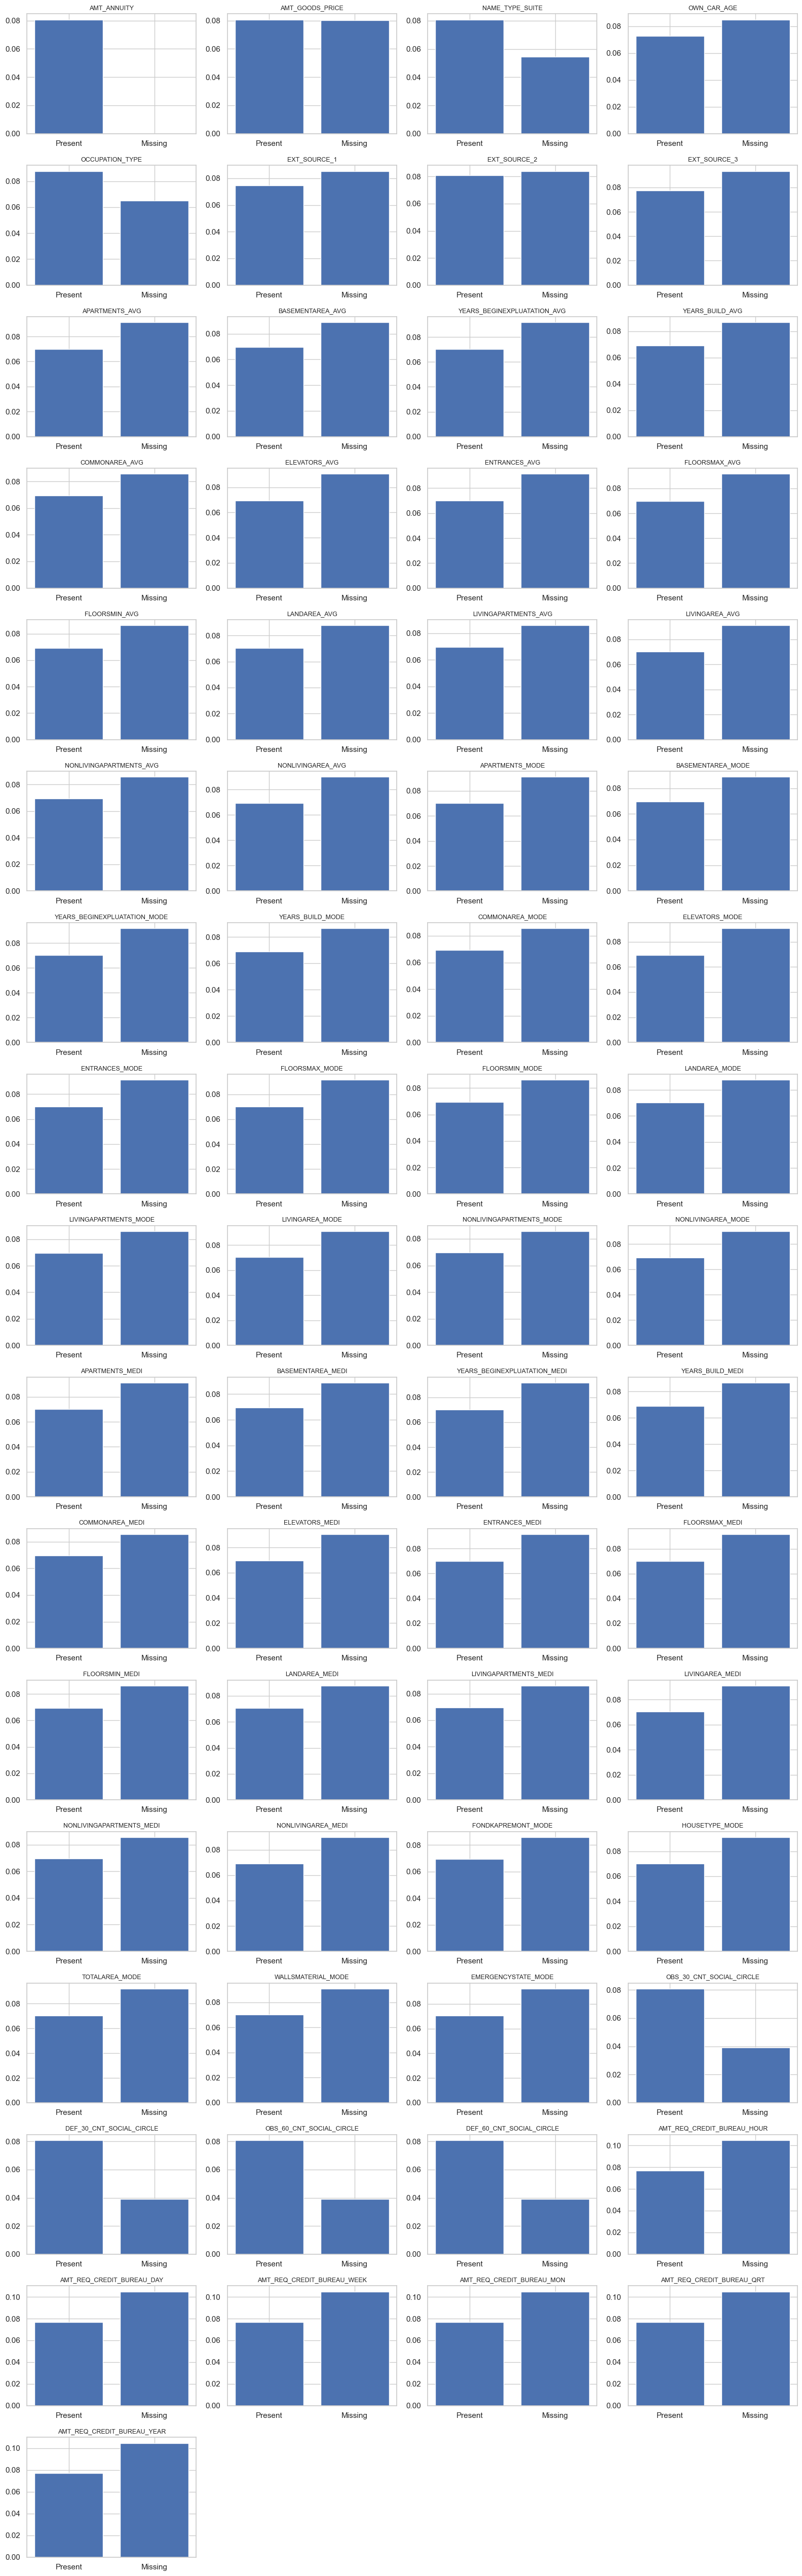

In [34]:
n_cols = 4
n_rows = -(-len(features_with_na) // n_cols)  # ceiling division
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))

for feature, ax in zip(features_with_na, axes.ravel()):
    data = eda_df.copy()
    data[feature] = np.where(data[feature].isnull(), 1, 0)
    rates = data.groupby(feature)["TARGET"].mean()
    ax.bar(["Present", "Missing"], rates.values)
    ax.set_title(feature, fontsize=9)

# hide any unused subplot axes
for ax in axes.ravel()[len(features_with_na):]:
    ax.axis("off")

plt.tight_layout()
plt.show()